
### 1. Input

De dataset bevat kunstmatig gegenereerde afbeeldingen van drie bacterievormen: rond, spiraal en staaf. Elke afbeelding bestaat uit 32 × 32 pixels in grijswaarden.

De dataset is verdeeld in trainingsdata (300 afbeeldingen), validatiedata (60 afbeeldingen) en testdata (60 afbeeldingen).

**Hyperparameters:**
- `image_size`: afbeeldingsgrootte (32 × 32 pixels).
- `batch_size`: aantal afbeeldingen dat tegelijk wordt verwerkt.


In [1]:

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Afbeeldingen omzetten naar tensors met één kleurkanaal
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()
])

# Datasets laden
train_dataset = datasets.ImageFolder("dataset/train", transform=transform)
validation_dataset = datasets.ImageFolder("dataset/validation", transform=transform)
test_dataset = datasets.ImageFolder("dataset/test", transform=transform)

# Hyperparameter
batch_size = 10

# DataLoaders aanmaken
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Dataset controleren
print("Klassen:", train_dataset.classes)
print("Training:", len(train_dataset))
print("Validatie:", len(validation_dataset))
print("Test:", len(test_dataset))

afbeeldingen, targets = next(iter(train_loader))
print("Inputvorm:", afbeeldingen.shape)


Klassen: ['rond', 'spiraal', 'staaf']
Training: 300
Validatie: 60
Test: 60
Inputvorm: torch.Size([10, 1, 32, 32])



### 2. Filter

Een filter is een kleine matrix met gewichten waarmee kenmerken in een afbeelding worden herkend, zoals randen en vormen. 

De gewichten worden tijdens de training automatisch aangepast.

1 convolutionele hidden layer met 8 filters.

**Hyperparameters:**
- `in_channels`: aantal invoerkanalen.
- `out_channels`: aantal filters.
- `kernel_size`: afmeting van elk filter.


In [2]:

import torch.nn as nn

# Convolutionele laag met 8 filters van 3 × 3
conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=8,
    kernel_size=3
)

# Afmetingen en aantal filters controleren
print("Filters:", conv1.weight.shape)
print("Aantal filters:", conv1.out_channels)

Filters: torch.Size([8, 1, 3, 3])
Aantal filters: 8



### 3. Convolutie

Bij convolutie schuiven de filters over de afbeelding. Op elke positie worden de pixelwaarden vermenigvuldigd met de filtergewichten. De resultaten worden opgeteld en de bias wordt toegevoegd.

De convolutionele laag levert voor elk filter een feature map op.

Feature map = Afbeeldingsgrootte - Filtergrootte + stride

Feature map = 32x32 : 32 - 3 + 1 = 30 dus een feature map is 30x30


**Hyperparameters:**
- `stride`: aantal pixels waarmee het filter verschuift (standaard 1).
- `padding`: aantal extra pixels rondom de afbeelding (standaard 0).


In [ ]:

# De 10 afbeeldingen (uit één batch) door de convolutionele laag verwerken
conv_output = conv1(afbeeldingen)

# Afmetingen controleren
print("Input:", afbeeldingen.shape)
print("Output:", conv_output.shape)

Input: torch.Size([10, 1, 32, 32])
Output: torch.Size([10, 8, 30, 30])



### 4. Feature map

Een feature map is het resultaat van een filter dat over een afbeelding schuift. 

De waarden geven aan hoe sterk het filter reageert op bepaalde kenmerken.

De convolutionele laag levert per afbeelding 8 feature maps van 30 × 30 pixels op.

**Hyperparameters:** Geen. Het aantal en de afmetingen van de feature maps worden bepaald door de instellingen van de convolutionele laag.


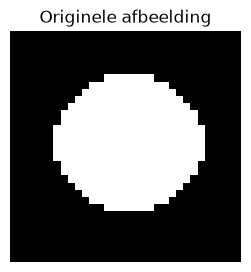

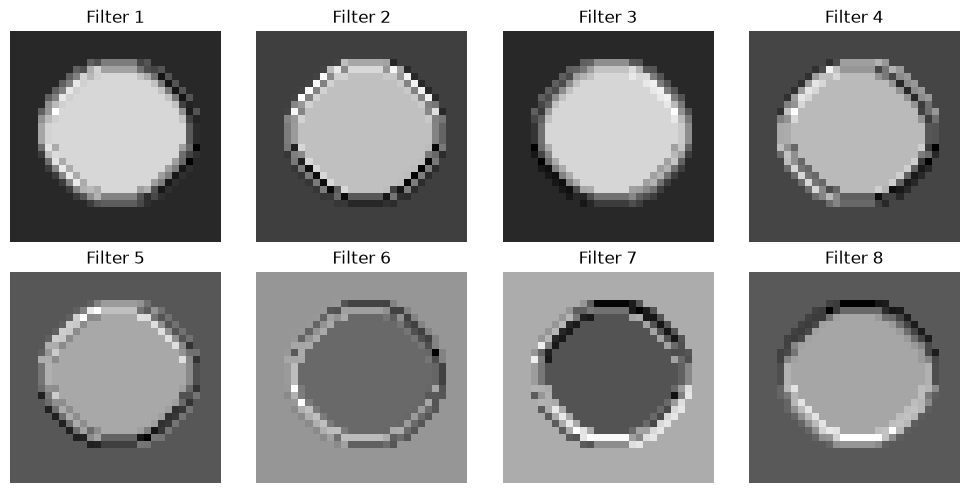

In [4]:

import matplotlib.pyplot as plt

# Eerste afbeelding uit de batch selecteren
afbeelding = afbeeldingen[0, 0]

# Feature maps van deze afbeelding selecteren
feature_maps = conv_output[0]

# Originele afbeelding tonen
plt.figure(figsize=(3, 3))
plt.imshow(afbeelding, cmap="gray", vmin=0, vmax=1)
plt.title("Originele afbeelding")
plt.axis("off")
plt.show()

# De 8 feature maps tonen
fig, assen = plt.subplots(2, 4, figsize=(10, 5))

for nummer, as_ in enumerate(assen.flat):
    as_.imshow(feature_maps[nummer].detach(), cmap="gray")
    as_.set_title(f"Filter {nummer + 1}")
    as_.axis("off")

plt.tight_layout()
plt.show()



### 5. ReLU - activatiefunctie

ReLU (Rectified Linear Unit) is een activatiefunctie die negatieve waarden omzet naar 0. Positieve waarden blijven ongewijzigd.

Hierdoor kan het CNN complexere patronen leren herkennen.

**Hyperparameters:** De standaard ReLU heeft geen instelbare hyperparameters.


In [5]:

# ReLU-activatiefunctie aanmaken
relu = nn.ReLU()

# ReLU toepassen op de feature maps
relu_output = relu(conv_output)

# Resultaat controleren
print("Voor ReLU:")
print("Minimum:", conv_output.min().item())

print("\nNa ReLU:")
print("Minimum:", relu_output.min().item())
print("Outputvorm:", relu_output.shape)

Voor ReLU:
Minimum: -0.7933393716812134

Na ReLU:
Minimum: 0.0
Outputvorm: torch.Size([10, 8, 30, 30])



### 6. Max Pooling

Max Pooling verkleint de feature maps door uit elk gebied de hoogste waarde te behouden. 

Hierdoor neemt de hoeveelheid te verwerken informatie af, terwijl sterke kenmerken behouden blijven.

In dit project worden de feature maps verkleind van 30×30 naar 15×15 pixels.

**Hyperparameters:**
- `kernel_size`: grootte van het gebied (2 × 2).
- `stride`: aantal pixels waarmee het gebied verschuift (standaard gelijk aan `kernel_size`).


In [6]:

# Max Pooling met gebieden van 2 × 2
pool = nn.MaxPool2d(kernel_size=2)

# Pooling toepassen na ReLU
pool_output = pool(relu_output)

# Afmetingen controleren
print("Voor pooling:", relu_output.shape)
print("Na pooling:", pool_output.shape)


Voor pooling: torch.Size([10, 8, 30, 30])
Na pooling: torch.Size([10, 8, 15, 15])



### 7. Flattening

Flattening zet de feature maps om naar één lange reeks getallen (vector). Hierdoor kunnen de waarden worden verwerkt door de Dense Layer.

De 8 feature maps van 15 × 15 pixels worden omgezet naar een vector van 1800 waarden per afbeelding.

Per afbeelding worden 8 x 15x15 = 1800 waarden samengevoegd. De batch bevat nog steeds 10 afbeeldingen

**Hyperparameters:** Flattening heeft geen instelbare hyperparameters.


In [7]:

# Flatten-laag aanmaken
flatten = nn.Flatten()

# Feature maps omzetten naar een vector
flatten_output = flatten(pool_output)

# Afmetingen controleren
print("Voor flattening:", pool_output.shape)
print("Na flattening:", flatten_output.shape)


Voor flattening: torch.Size([10, 8, 15, 15])
Na flattening: torch.Size([10, 1800])



### 8. Dense Layer / Classification

Een Dense Layer is een laag waarin elk neuron verbonden is met alle uitvoerwaarden van de vorige laag.

De eerste Dense Layer ontvangt 1800 waarden en bevat 32 neuronen. Dit is een **hidden layer**. Hierop wordt de ReLU-activatiefunctie toegepast.

De tweede Dense Layer is de **outputlaag**. Deze ontvangt 32 waarden en berekent 3 scores, één voor elke bacterieklasse.

**Hyperparameters:**
- `in_features`: aantal invoerwaarden.
- `out_features`: aantal neuronen.
- Aantal Dense-hidden layers. (Het aantal hidden layers is een architectuurkeuze.)


In [8]:

# Dense-hidden layer: 1800 invoerwaarden naar 32 neuronen
dense_hidden = nn.Linear(in_features=1800, out_features=32)

# Outputlaag: 32 neuronen naar 3 klassen
dense_output = nn.Linear(in_features=32, out_features=3)

# Hidden layer en ReLU toepassen
hidden_output = relu(dense_hidden(flatten_output))

# Klassenscores berekenen
scores = dense_output(hidden_output)

# Afmetingen controleren
print("Na flattening:", flatten_output.shape)
print("Na Dense-hidden layer:", hidden_output.shape)
print("Na outputlaag:", scores.shape)

# Scores van de eerste afbeelding
print("\nKlassenscores eerste afbeelding:")
for klasse, score in zip(train_dataset.classes, scores[0].detach()):
    print(f"{klasse}: {score.item():.4f}")


Na flattening: torch.Size([10, 1800])
Na Dense-hidden layer: torch.Size([10, 32])
Na outputlaag: torch.Size([10, 3])

Klassenscores eerste afbeelding:
rond: 0.1021
spiraal: -0.0358
staaf: -0.1470



### 9. Loss Function

De lossfunctie berekent hoe sterk de voorspellingen van het CNN afwijken van de juiste bacterieklassen. 

Een lagere loss betekent dat de voorspellingen beter aansluiten bij de juiste antwoorden.

`CrossEntropyLoss` is geschikt voor classificatie met meerdere klassen. 

De functie gebruikt de berekende klassenscores en de juiste klasse (`target`).

**Hyperparameter:**
- Type lossfunctie: `CrossEntropyLoss`.


In [9]:

# Lossfunctie aanmaken
loss_functie = nn.CrossEntropyLoss()

# Loss berekenen voor de huidige batch
loss = loss_functie(scores, targets)

# Resultaat tonen
print("Loss:", round(loss.item(), 4))


Loss: 1.131



### 10. Gradient

De gradient geeft aan hoe een verandering van een gewicht de loss beïnvloedt. Met deze informatie kan het CNN zijn gewichten tijdens de training aanpassen.

PyTorch berekent de gradients automatisch met `loss.backward()`. Dit proces heet *backpropagation*.

**Hyperparameters:** Geen. De gradients worden berekend op basis van de huidige gewichten en de lossfunctie.


In [10]:

# Eerder berekende gradients wissen
conv1.zero_grad()
dense_hidden.zero_grad()
dense_output.zero_grad()

# Gradients berekenen via backpropagation
loss.backward()

# Gradients van de eerste convolutionele laag controleren
print("Gradientvorm:", conv1.weight.grad.shape)
print("Gemiddelde absolute gradient:",
      round(conv1.weight.grad.abs().mean().item(), 6))


Gradientvorm: torch.Size([8, 1, 3, 3])
Gemiddelde absolute gradient: 0.008074



### 11. Optimizer

De optimizer past de gewichten en biases van het CNN aan op basis van de berekende gradients.

Het doel is om de loss tijdens de training te verlagen.

`SGD` (Stochastic Gradient Descent) past de parameters stapsgewijs aan.

**Hyperparameters:**
- `optimizer`: type optimalisatiemethode, bijvoorbeeld SGD of Adam.
- `learning rate` (`lr`): bepaalt hoe groot de aanpassing per stap is.
- `momentum`: kan bij SGD helpen om de aanpassingen in een consistente richting voort te zetten.


In [11]:

import torch.optim as optim

# Optimizer aanmaken voor alle trainbare lagen
optimizer = optim.SGD(
    list(conv1.parameters()) +
    list(dense_hidden.parameters()) +
    list(dense_output.parameters()),
    lr=0.01
)

# Gewicht vóór de aanpassing bewaren
gewicht_voor = conv1.weight[0, 0, 0, 0].item()

# Gewichten aanpassen op basis van de gradients
optimizer.step()

# Gewicht na de aanpassing controleren
gewicht_na = conv1.weight[0, 0, 0, 0].item()

print(f"Gewicht vóór: {gewicht_voor:.8f}")
print(f"Gewicht na:   {gewicht_na:.8f}")
print(f"Verschil:     {gewicht_na - gewicht_voor:.8f}")


Gewicht vóór: 0.03589642
Gewicht na:   0.03584134
Verschil:     -0.00005508



### 12. CNN-model

De afzonderlijke lagen worden samengevoegd tot één CNN-model. 

De afbeeldingen worden achtereenvolgens verwerkt door convolutie, ReLU, Max Pooling, Flattening en de Dense Layers.

Met class BacterieCNN(nn.Module) worden alle afzonderlijke lagen samengebracht in één model. 

De methode forward() bepaalt in welke volgorde de gegevens door het netwerk gaan.

Het voordeel is dat straks niet meer iedere laag afzonderlijk hoeft aan te roepen worden.

Het model bevat één convolutionele hidden layer met 8 filters, één Dense-hidden layer met 32 neuronen en één outputlaag met 3 neuronen.

**Hyperparameters:** De architectuur en het aantal neuronen en filters zijn vastgelegd in de voorgaande onderdelen.


In [12]:

# CNN-model definiëren
class BacterieCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 8, kernel_size=3)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.flatten = nn.Flatten()

        self.dense_hidden = nn.Linear(1800, 32)
        self.dense_output = nn.Linear(32, 3)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.flatten(x)
        x = self.dense_hidden(x)
        x = self.relu(x)
        x = self.dense_output(x)

        return x


# Nieuw CNN-model aanmaken
model = BacterieCNN()

# Modelstructuur tonen
print(model)

# Aantal trainbare parameters berekenen
aantal_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nAantal trainbare parameters:", aantal_parameters)


BacterieCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (dense_hidden): Linear(in_features=1800, out_features=32, bias=True)
  (dense_output): Linear(in_features=32, out_features=3, bias=True)
)

Aantal trainbare parameters: 57811



### 13. Training en validatie

Tijdens de training verwerkt het CNN de trainingsafbeeldingen en past het de gewichten aan om de loss te verlagen.

Na iedere epoch wordt het model gecontroleerd met de validatiedataset. Hierbij worden de loss en de nauwkeurigheid (*accuracy*) berekend.

De validatiegegevens worden niet gebruikt om de gewichten aan te passen.

**Hyperparameters:**
- `epochs`: aantal keren dat de volledige trainingsdataset wordt verwerkt.
- `batch_size`: aantal afbeeldingen per trainingsstap (10).
- `learning rate`: grootte van de gewichtsaanpassingen (0.01).
- `optimizer`: optimalisatiemethode (SGD).


In [13]:

# Lossfunctie en optimizer instellen
loss_functie = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

# Hyperparameter
epochs = 70

# Resultaten per epoch bewaren
train_losses = []
validation_losses = []
validation_accuracies = []

for epoch in range(epochs):

    # TRAINING
    model.train()
    totale_train_loss = 0

    for afbeeldingen, targets in train_loader:

        optimizer.zero_grad()

        scores = model(afbeeldingen)
        loss = loss_functie(scores, targets)

        loss.backward()
        optimizer.step()

        totale_train_loss += loss.item() * afbeeldingen.size(0)

    gemiddelde_train_loss = totale_train_loss / len(train_dataset)
    train_losses.append(gemiddelde_train_loss)

    # VALIDATIE
    model.eval()
    totale_validation_loss = 0
    aantal_correct = 0

    with torch.no_grad():
        for afbeeldingen, targets in validation_loader:

            scores = model(afbeeldingen)
            loss = loss_functie(scores, targets)

            totale_validation_loss += loss.item() * afbeeldingen.size(0)

            voorspellingen = scores.argmax(dim=1)
            aantal_correct += (voorspellingen == targets).sum().item()

    gemiddelde_validation_loss = (
        totale_validation_loss / len(validation_dataset)
    )
    accuracy = 100 * aantal_correct / len(validation_dataset)

    validation_losses.append(gemiddelde_validation_loss)
    validation_accuracies.append(accuracy)

    # Resultaten iedere 10 epochs tonen
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:2d}/{epochs} | "
            f"Train loss: {gemiddelde_train_loss:.4f} | "
            f"Validation loss: {gemiddelde_validation_loss:.4f} | "
            f"Accuracy: {accuracy:.1f}%"
        )


Epoch  1/70 | Train loss: 1.0792 | Validation loss: 1.0476 | Accuracy: 41.7%
Epoch 10/70 | Train loss: 0.2536 | Validation loss: 0.2179 | Accuracy: 98.3%
Epoch 20/70 | Train loss: 0.0709 | Validation loss: 0.0581 | Accuracy: 98.3%
Epoch 30/70 | Train loss: 0.0285 | Validation loss: 0.0288 | Accuracy: 100.0%
Epoch 40/70 | Train loss: 0.0147 | Validation loss: 0.0158 | Accuracy: 100.0%
Epoch 50/70 | Train loss: 0.0092 | Validation loss: 0.0120 | Accuracy: 100.0%
Epoch 60/70 | Train loss: 0.0065 | Validation loss: 0.0089 | Accuracy: 100.0%
Epoch 70/70 | Train loss: 0.0048 | Validation loss: 0.0069 | Accuracy: 100.0%



### 14. Trainings- en validatieloss

De grafiek toont het verloop van de trainingsloss en validatieloss gedurende 70 epochs.

Door beide lijnen te vergelijken, kun je beoordelen of het CNN nog echt nieuwe dingen leert, 

of dat het de trainingsdata simpelweg uit zijn hoofd begint te leren (overfitting).


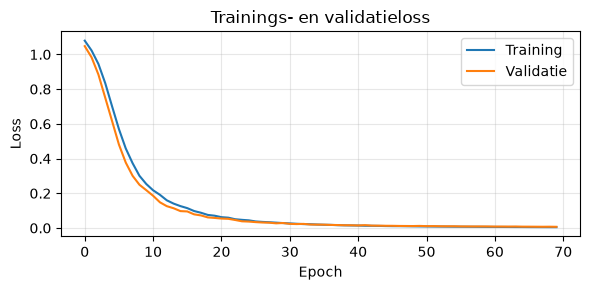

In [14]:

import matplotlib.pyplot as plt

# grafiek
plt.figure(figsize=(6, 3))

plt.plot(train_losses, label="Training")
plt.plot(validation_losses, label="Validatie")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Trainings- en validatieloss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 15. Testen van het CNN

Het getrainde CNN wordt beoordeeld met 60 testafbeeldingen die niet tijdens de training of validatie zijn gebruikt.

De testloss geeft aan hoe sterk de voorspellingen afwijken van de juiste klassen. 

De nauwkeurigheid (*accuracy*) geeft het percentage correct geclassificeerde afbeeldingen aan.

**Hyperparameters:** Geen nieuwe. Het getrainde model en de bestaande lossfunctie worden gebruikt.


In [15]:

# Model instellen op evaluatiemode
model.eval()

totale_test_loss = 0
aantal_correct = 0

# Testen zonder gewichten aan te passen
with torch.no_grad():
    for afbeeldingen, targets in test_loader:

        scores = model(afbeeldingen)
        loss = loss_functie(scores, targets)

        totale_test_loss += loss.item() * afbeeldingen.size(0)

        # Voorspelde klasse bepalen
        voorspellingen = scores.argmax(dim=1)
        aantal_correct += (voorspellingen == targets).sum().item()

# Gemiddelde testloss en nauwkeurigheid berekenen
gemiddelde_test_loss = totale_test_loss / len(test_dataset)
test_accuracy = 100 * aantal_correct / len(test_dataset)

print(f"Testloss: {gemiddelde_test_loss:.4f}")
print(f"Correct geclassificeerd: {aantal_correct}/{len(test_dataset)}")
print(f"Testnauwkeurigheid: {test_accuracy:.1f}%")


Testloss: 0.0730
Correct geclassificeerd: 59/60
Testnauwkeurigheid: 98.3%


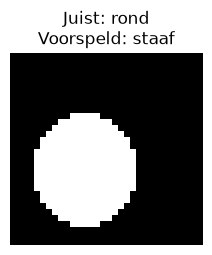

In [16]:

# Verkeerd geclassificeerde testafbeeldingen zoeken
model.eval()

with torch.no_grad():
    for afbeeldingen, targets in test_loader:
        scores = model(afbeeldingen)
        voorspellingen = scores.argmax(dim=1)

        for afbeelding, target, voorspelling in zip(
            afbeeldingen, targets, voorspellingen
        ):
            if voorspelling != target:
                plt.figure(figsize=(2.5, 2.5))
                plt.imshow(afbeelding[0], cmap="gray")
                plt.title(
                    f"Juist: {test_dataset.classes[target.item()]}\n"
                    f"Voorspeld: {test_dataset.classes[voorspelling.item()]}"
                )
                plt.axis("off")
                plt.show()



### 16. Model opslaan

De getrainde gewichten en biases van het CNN worden opgeslagen in een `.pth`-bestand. Hierdoor kan het model later opnieuw worden gebruikt zonder opnieuw te trainen.

De opbouw van het CNN staat in de Python-klasse BacterieCNN. Het .pth-bestand bevat de getrainde gewichten en biases.

In [17]:

from pathlib import Path

# Map voor het model aanmaken
modelmap = Path("modellen")
modelmap.mkdir(exist_ok=True)

# Getrainde parameters opslaan
modelbestand = modelmap / "bacterie_cnn_32x32.pth"
torch.save(model.state_dict(), modelbestand)

print("Model opgeslagen:", modelbestand)


Model opgeslagen: modellen\bacterie_cnn_32x32.pth



### 17. Conclusie

Een Convolutional Neural Network (CNN) is ontwikkeld en getraind om drie kunstmatig gegenereerde bacterievormen te classificeren: rond, spiraal en staaf.

Na 70 epochs behaalde het model een validatienauwkeurigheid van 100%. 

Bij de onafhankelijke test werden 59 van de 60 afbeeldingen correct geclassificeerd, een nauwkeurigheid van 98,3%.

De trainings- en validatieloss daalden gedurende de training. Er waren geen duidelijke aanwijzingen voor overfitting.

De resultaten laten zien dat het CNN de gegenereerde vormen goed kan onderscheiden. 

Omdat uitsluitend kunstmatige afbeeldingen zijn gebruikt, kunnen geen conclusies worden getrokken over de herkenning van echte bacteriën.
